# Final Mass
After speaking with Donelan lab, final mass is also an interesting metric - we assume that all oysters started at roughly the same size and then ask what is the final mass/size of the oyster (and smaller oysters tend to grow faster)

So going to look at the final mass of the sequenced oysters (and compare against the full data set)

## 0. load libraries

In [2]:
library(tidyverse)
library(cowplot) # add plots together
library(grid)
library(RColorBrewer)

# for stat testing
library(lme4) # for linear mixed effects model
library(ggpubr)
library(car)
library(rstatix)

## 1. read CSVs

#### metadata
to pull out sequenced oysters

In [36]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv')
head(meta)

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1
2,B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5
4,B2_B5_O51,both,warm,hypoxic,2,both,warm,hypoxic,5
5,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4
6,B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA


#### phase 1

In [24]:
p1.mass <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase1_weights.csv') %>%
# consistent sample naming
mutate(Sample = paste0(substr(Phase_1_treat,1,1), Phase_1_rep, '_Nu_', Tag_color, sprintf("%02d", Tag_num))) %>%
# pull final mass columns and metadata
select(Sample, 'Phase1_treatment' = Phase_1_treat, 'Phase1_temp' = Phase_1_temp, 'Phase1_DO' = Phase_1_DO, 
       Actual_tissue_post_mg, Actual_shell_post_mg)

colnames(p1.mass)
head(p1.mass)

[1] "Sample"                "Phase1_treatment"      "Phase1_temp"          
[4] "Phase1_DO"             "Actual_tissue_post_mg" "Actual_shell_post_mg"

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Actual_tissue_post_mg,Actual_shell_post_mg
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,B1_Nu_O01,Both,Warm,Hyp,46.25846,73.04154
2,B1_Nu_O02,Both,Warm,Hyp,75.59046,104.70954
3,B1_Nu_O03,Both,Warm,Hyp,60.96492,117.53508
4,B1_Nu_O04,Both,Warm,Hyp,215.11878,223.78122
5,B1_Nu_O05,Both,Warm,Hyp,3.56948,9.23052
6,B1_Nu_O06,Both,Warm,Hyp,173.42636,241.67364


In [38]:
# pull out only the sequenced oysters
p1.mass <- p1.mass[p1.mass$Sample %in% meta$Sample,]

In [41]:
p1.mass$Phase1_treatment <- factor(p1.mass$Phase1_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))

#### phase 2

In [60]:
p2.mass <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase2.1_weights.csv') %>%
# consistent sample naming
mutate(Sample = paste0(substr(Phase_1_treat,1,1), Phase_1_rep, '_', substr(Phase_2_treat,1,1), Phase_2_rep, '_', Tag_color, sprintf("%02d", Tag_num))) %>%
# pull final mass columns and metadata
select(Sample, 'Phase1_treatment' = Phase_1_treat, 'Phase1_temp' = Phase_1_temp, 'Phase1_DO' = Phase_1_DO, 
       'Phase2_treatment' = Phase_2_treat, 'Phase2_temp' = Phase_2.1_temp, 'Phase2_DO' = Phase_2.1_DO,
       Actual_tissue_post_mg, Actual_shell_post_mg) 

colnames(p2.mass)
head(p2.mass)

[1] "Sample"                "Phase1_treatment"      "Phase1_temp"          
[4] "Phase1_DO"             "Phase2_treatment"      "Phase2_temp"          
[7] "Phase2_DO"             "Actual_tissue_post_mg" "Actual_shell_post_mg"

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase2_treatment,Phase2_temp,Phase2_DO,Actual_tissue_post_mg,Actual_shell_post_mg
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
1,B1_B1_O01,Both,Warm,Hyp,Both,Warm,Hyp,419.7304,541.5696
2,B1_B1_O02,Both,Warm,Hyp,Both,Warm,Hyp,293.8024,613.2976
3,B1_B2_O13,Both,Warm,Hyp,Both,Warm,Hyp,373.3559,727.1441
4,B1_B2_O14,Both,Warm,Hyp,Both,Warm,Hyp,366.8839,655.4161
5,B1_B3_O25,Both,Warm,Hyp,Both,Warm,Hyp,111.7034,193.6966
6,B1_B3_O26,Both,Warm,Hyp,Both,Warm,Hyp,200.2005,460.4995


In [61]:
# pull out only the sequenced oysters
p2.mass <- p2.mass[p2.mass$Sample %in% meta$Sample,]

In [62]:
p2.mass$Phase1_treatment <- factor(p2.mass$Phase1_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))
p2.mass$Phase2_treatment <- factor(p2.mass$Phase2_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))

## 2. phase 1 final mass

### tissue

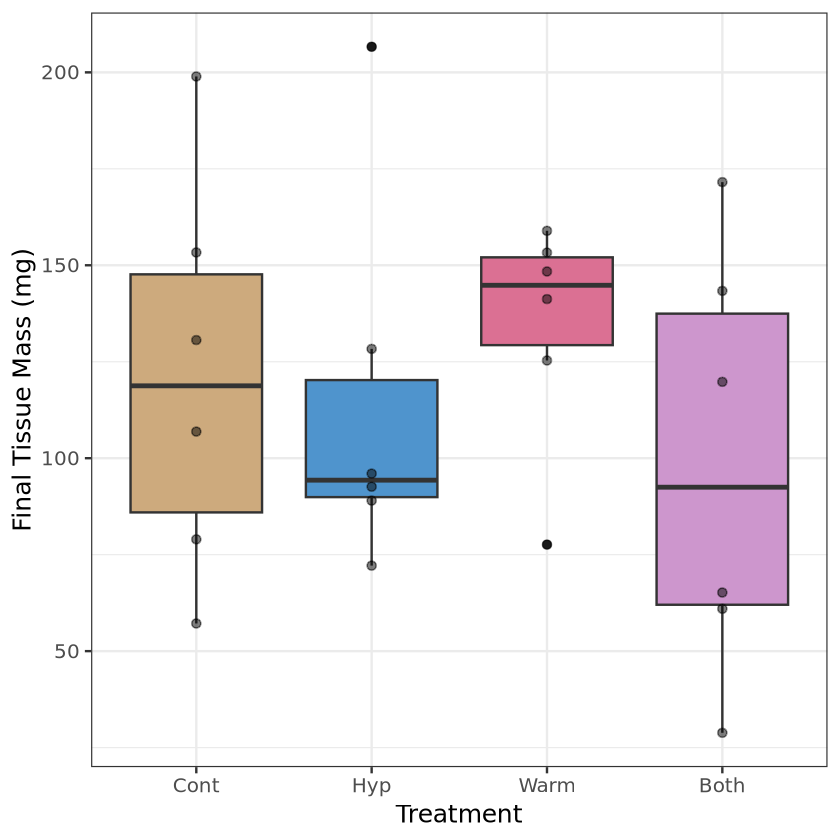

In [42]:
ggplot(p1.mass, aes(x = Phase1_treatment, y = Actual_tissue_post_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
labs(x = 'Treatment',
     y = 'Final Tissue Mass (mg)') +
theme_bw(base_size = 15)

#### stat testing:

In [44]:
m1 <- aov(Actual_tissue_post_mg ~ Phase1_DO*Phase1_temp, data = p1.mass)
summary(m1)

                      Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO              1   2736  2736.3   1.219  0.283
Phase1_temp            1     11    10.9   0.005  0.945
Phase1_DO:Phase1_temp  1   1261  1260.5   0.562  0.462
Residuals             20  44877  2243.9               

no significant difference of final mass between treatments

### shell

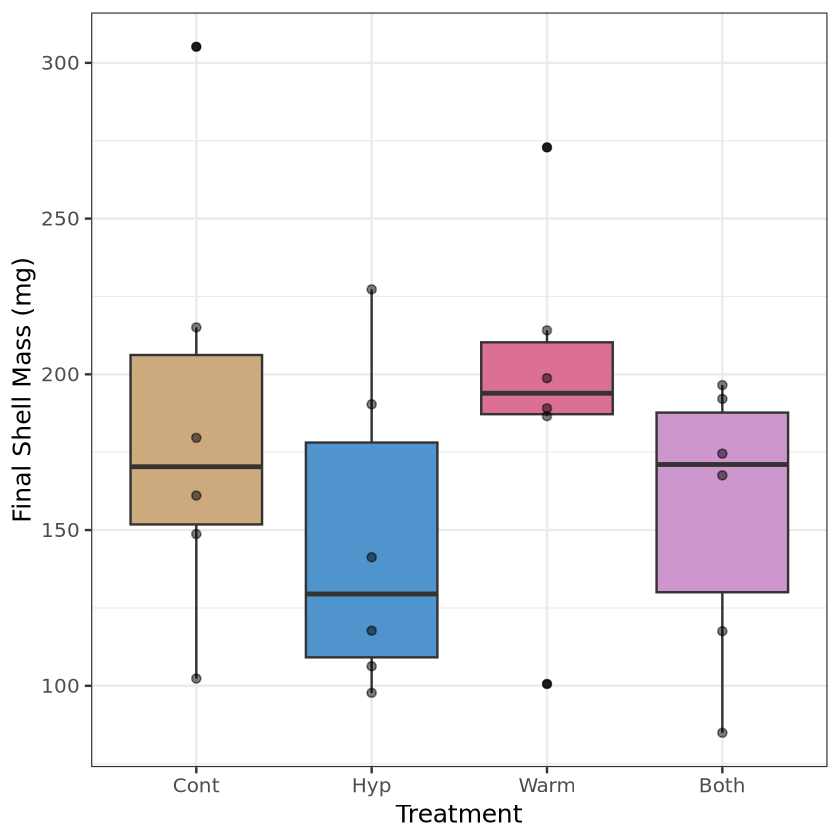

In [43]:
ggplot(p1.mass, aes(x = Phase1_treatment, y = Actual_shell_post_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
labs(x = 'Treatment',
     y = 'Final Shell Mass (mg)') +
theme_bw(base_size = 15)

#### stat testing:

In [45]:
m2 <- aov(Actual_shell_post_mg ~ Phase1_DO*Phase1_temp, data = p1.mass)
summary(m2)

                      Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO              1   8822    8822   2.809  0.109
Phase1_temp            1    439     439   0.140  0.713
Phase1_DO:Phase1_temp  1      0       0   0.000  0.993
Residuals             20  62800    3140               

no significant difference between treatments

## 3. phase 2 final mass

### tissue

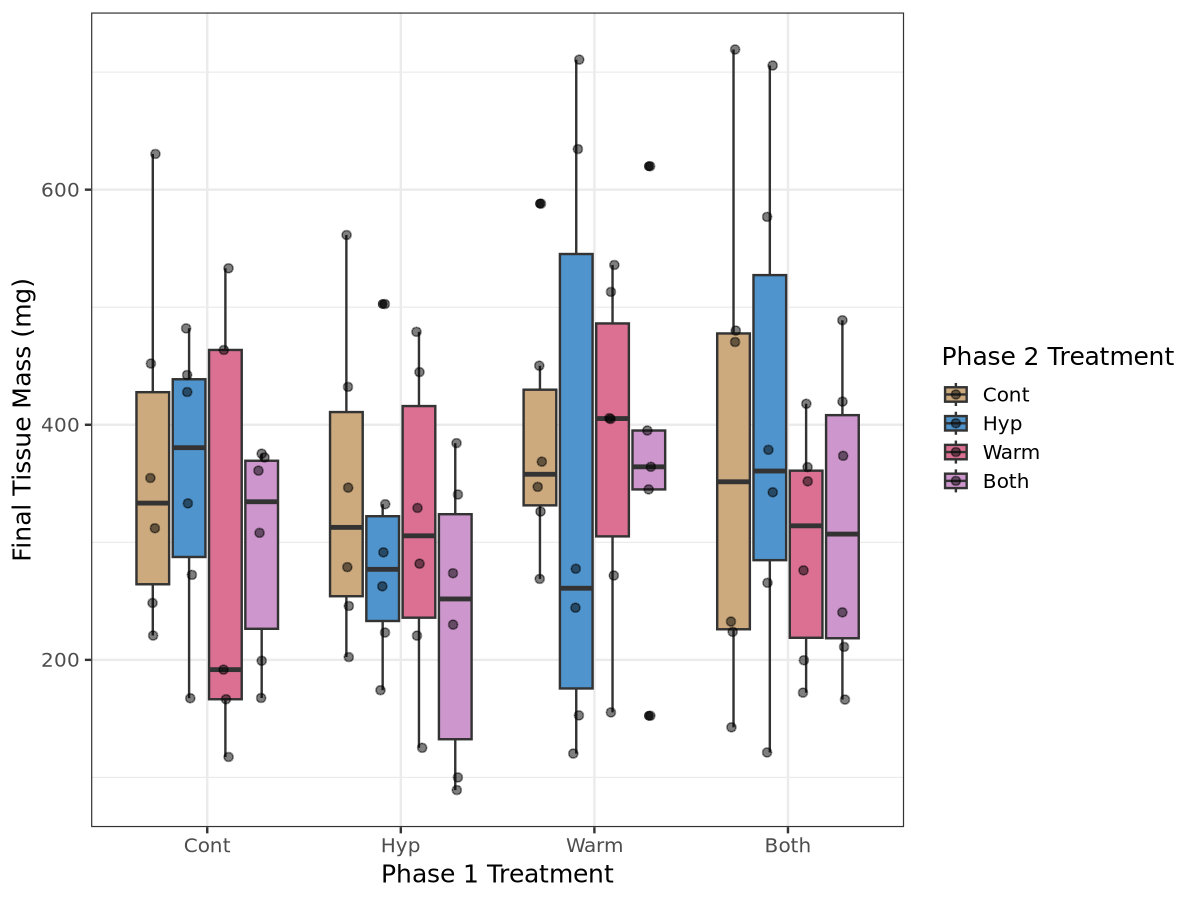

In [65]:
options(repr.plot.height = 7.5, repr.plot.width = 10)

ggplot(p2.mass, aes(x = Phase1_treatment, y = Actual_tissue_post_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Final Tissue Mass (mg)') +
theme_bw(base_size = 15)

#### stat testing:

In [67]:
m3 <- aov(Actual_tissue_post_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.mass)
summary(m3)

                                            Df  Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1   21877   21877   0.907  0.344
Phase1_temp                                  1   53478   53478   2.217  0.141
Phase2_DO                                    1    7817    7817   0.324  0.571
Phase2_temp                                  1   53436   53436   2.215  0.141
Phase1_DO:Phase1_temp                        1     119     119   0.005  0.944
Phase1_DO:Phase2_DO                          1     177     177   0.007  0.932
Phase1_temp:Phase2_DO                        1    6877    6877   0.285  0.595
Phase1_DO:Phase2_temp                        1    6736    6736   0.279  0.599
Phase1_temp:Phase2_temp                      1    1450    1450   0.060  0.807
Phase2_DO:Phase2_temp                        1      34      34   0.001  0.970
Phase1_DO:Phase1_temp:Phase2_DO              1   13542   13542   0.561  0.456
Phase1_DO:Phase1_temp:Phase2_temp            1   15982   15982  

no significant difference of final mass between treatments

### shell

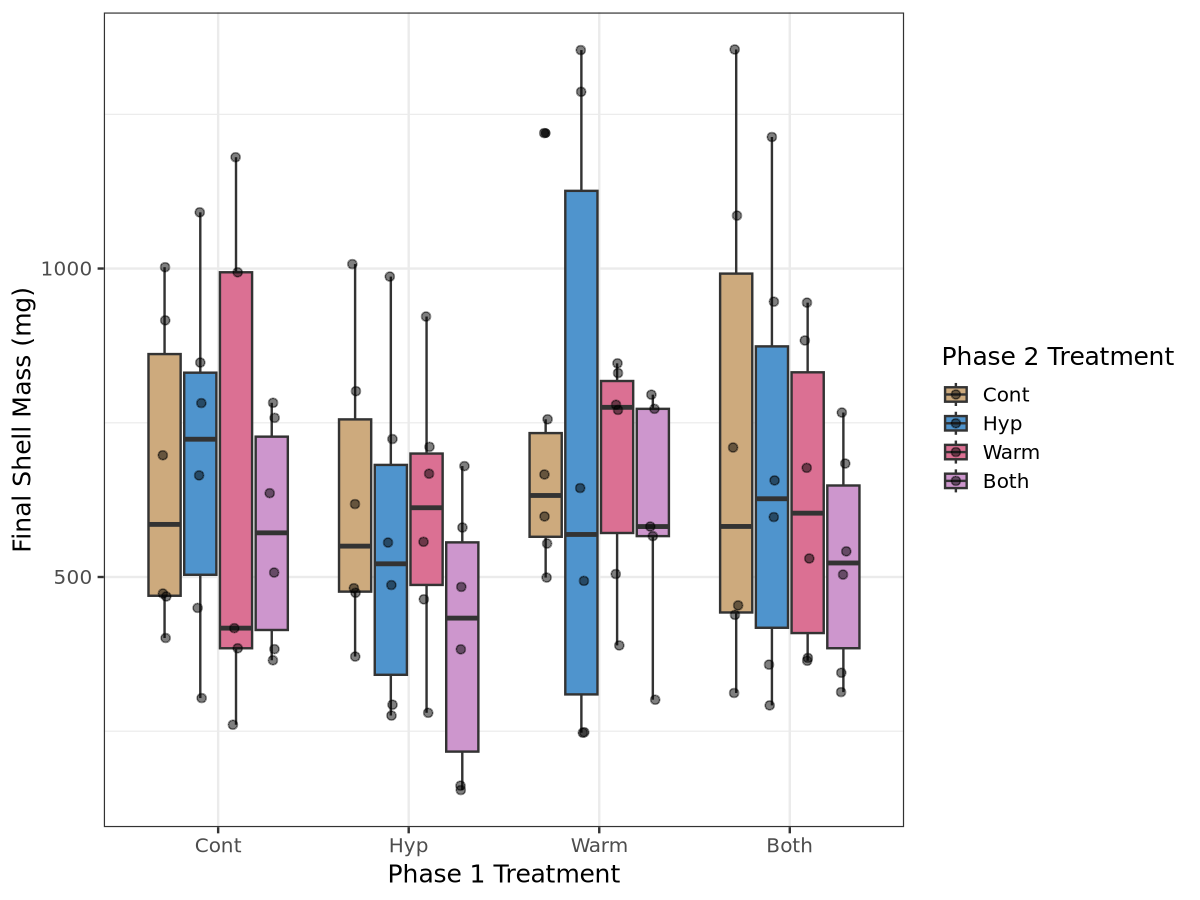

In [68]:
ggplot(p2.mass, aes(x = Phase1_treatment, y = Actual_shell_post_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Final Shell Mass (mg)') +
theme_bw(base_size = 15)

#### stat testing:

In [69]:
m4 <- aov(Actual_shell_post_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.mass)
summary(m4)

                                            Df  Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1  113404  113404   1.349  0.249
Phase1_temp                                  1  106251  106251   1.264  0.264
Phase2_DO                                    1  107359  107359   1.278  0.262
Phase2_temp                                  1  175623  175623   2.090  0.152
Phase1_DO:Phase1_temp                        1   17509   17509   0.208  0.649
Phase1_DO:Phase2_DO                          1   31546   31546   0.375  0.542
Phase1_temp:Phase2_DO                        1    1886    1886   0.022  0.881
Phase1_DO:Phase2_temp                        1    8890    8890   0.106  0.746
Phase1_temp:Phase2_temp                      1    2216    2216   0.026  0.871
Phase2_DO:Phase2_temp                        1   47956   47956   0.571  0.452
Phase1_DO:Phase1_temp:Phase2_DO              1    8964    8964   0.107  0.745
Phase1_DO:Phase1_temp:Phase2_temp            1    1815    1815  

no significant effect of treatments on final mass of the oyster

## 4. conclusions:

similar to [growth](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/phenotype_data/growth/growth_treatments.ipynb), I do not see any significant differences in final mass between oysters that experienced different treatments/combination of treatments